# Model: Bitcoin price prediction (tomorrow's close)
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella  | **Dataset:** [Bitcoin Price Prediction (Kaggle, team-ai)](https://www.kaggle.com/team-ai/bitcoin-price-prediction) — files `bitcoin_price_Training` and `bitcoin_price_1week_Test` | **Type:** regression (time series)

This notebook follows the project template and leaves the model ready for the API (`models/bitcoin.joblib` + `predictors/bitcoin.py`).

Voice command: *"JarvisTEC, bitcoin price for tomorrow"*

## 1. Problem analysis (0.5 pt)

**What do we want to predict?** The closing price (USD) of bitcoin for the **next day**, to answer commands such as *"JarvisTEC, bitcoin price for tomorrow"*.

**Why is it hard?** Bitcoin is very volatile and, according to the efficient market hypothesis (Fama, 1970), the price changes of a financial asset are almost unpredictable from its own history. That is why, besides training models, we must compare them against a **naive baseline**: *"tomorrow's price will equal today's"* (Hyndman and Athanasopoulos, 2021). A model is only useful if it improves on that baseline. The literature applies ML to bitcoin prices by comparing statistical models and neural networks (McNally et al., 2018).

**Design decisions**
- **Target variable:** the *log return* of the next day, `ln(close_t+1 / close_t)`, not the price itself. The price is not stationary (it goes from ~\$68 to ~\$2,958 in the dataset) and tree models cannot predict values outside the range seen in training. The price is rebuilt as `close_t · exp(predicted_return)`.
- **Input features:** derived only from the closing-price series (recent returns, volatility and distance to moving averages). This way the API can use new data with just a list of closing prices.
- **Metrics:** RMSE and MAE in USD (on the price), MAPE, R² of the return and directional accuracy (does it go up or down?).
- **Success criterion:** beat the naive baseline on validation and test.

## 2. Data understanding (0.5 pt)

| Column | Meaning |
|---|---|
| `Date` | Date (one record per day) |
| `Open`, `High`, `Low`, `Close` | Opening, highest, lowest and closing price of the day (USD) |
| `Volume` | Volume traded in USD |
| `Market Cap` | Market capitalization in USD |

- **Training:** 2013-04-28 to 2017-07-31 (1,556 days). **Test:** 1–7 August 2017 (7 days), a separate file used only at the end.
- **Target variable:** the next day's `Close`. The files use thousands separators and mark missing volume with `-`, so they are cleaned while loading.

In [1]:
import sys, warnings, joblib
sys.path.insert(0, '..')          # to import predictors/
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from predictors.bitcoin import build_features, FEATURES   # same function the API uses

sns.set_theme(style='whitegrid'); warnings.filterwarnings('ignore')
RANDOM_STATE = 42
print('scikit-learn', sklearn.__version__)

def load(path):
    d = pd.read_csv(path, thousands=',', na_values='-')
    d['Date'] = pd.to_datetime(d['Date'], format='%b %d, %Y')
    return d.sort_values('Date').reset_index(drop=True)

train = load('../data/bitcoin_price_Training.csv')
test  = load('../data/bitcoin_price_1week_Test.csv')
train.head()

scikit-learn 1.8.0


,Date,Open,High,Low,Close,Volume,Market Cap
0,2013-04-28,135.30,135.98,132.10,134.21,NaN,1500520000
1,2013-04-29,134.44,147.49,134.00,144.54,NaN,1491160000
2,2013-04-30,144.00,146.93,134.05,139.00,NaN,1597780000
3,2013-05-01,139.00,139.89,107.72,116.99,NaN,1542820000
4,2013-05-02,116.38,125.60,92.28,105.21,NaN,1292190000


In [2]:
train.info()
train.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1556 entries, 0 to 1555
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        1556 non-null   datetime64[us]
 1   Open        1556 non-null   float64       
 2   High        1556 non-null   float64       
 3   Low         1556 non-null   float64       
 4   Close       1556 non-null   float64       
 5   Volume      1313 non-null   float64       
 6   Market Cap  1556 non-null   int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 85.2 KB


,Date,Open,High,Low,Close,Volume,Market Cap
count,1556,1556.000000,1556.000000,1556.000000,1556.000000,1.313000e+03,1.556000e+03
mean,2015-06-14 12:00:00,582.625328,597.992847,567.851446,584.239396,1.481643e+08,8.694353e+09
min,2013-04-28 00:00:00,68.500000,74.560000,65.530000,68.430000,2.857830e+06,7.792550e+08
25%,2014-05-21 18:00:00,254.287500,260.327500,248.835000,254.320000,2.071070e+07,3.598355e+09
50%,2015-06-14 12:00:00,438.600000,447.560000,430.570000,438.855000,4.530140e+07,6.386210e+09
75%,2016-07-07 06:00:00,662.437500,674.525000,646.735000,663.402500,9.037880e+07,9.898830e+09
max,2017-07-31 00:00:00,2953.220000,2999.910000,2840.530000,2958.110000,2.569530e+09,4.839120e+10
std,NaN,523.137312,542.992855,505.877401,525.904442,3.242987e+08,8.707288e+09


## 3. Data exploration (0.5 pt)
Missing values, date continuity, price evolution, return distribution, extreme values and autocorrelation.

In [3]:
print('Nulls per column:'); print(train.isna().sum())
print('\nLast day without volume:', train.loc[train['Volume'].isna(), 'Date'].max().date())
print('Days between consecutive records:', train['Date'].diff().dt.days.value_counts().to_dict())
print('Duplicates:', train.duplicated('Date').sum())

Nulls per column:
Date            0
Open            0
High            0
Low             0
Close           0
Volume        243
Market Cap      0
dtype: int64

Last day without volume: 2013-12-26
Days between consecutive records: {1.0: 1555}
Duplicates: 0


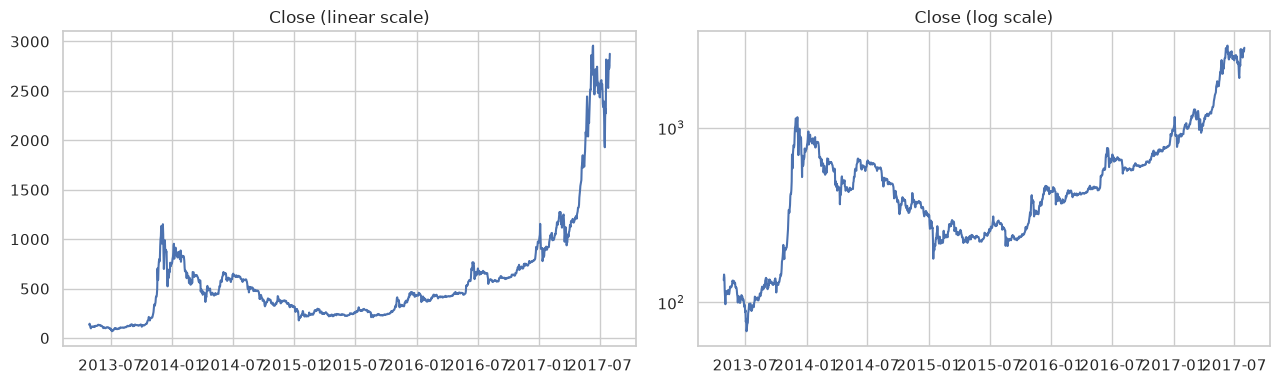

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(train['Date'], train['Close']); ax[0].set_title('Close (linear scale)')
ax[1].plot(train['Date'], train['Close']); ax[1].set_yscale('log'); ax[1].set_title('Close (log scale)')
plt.tight_layout(); plt.show()

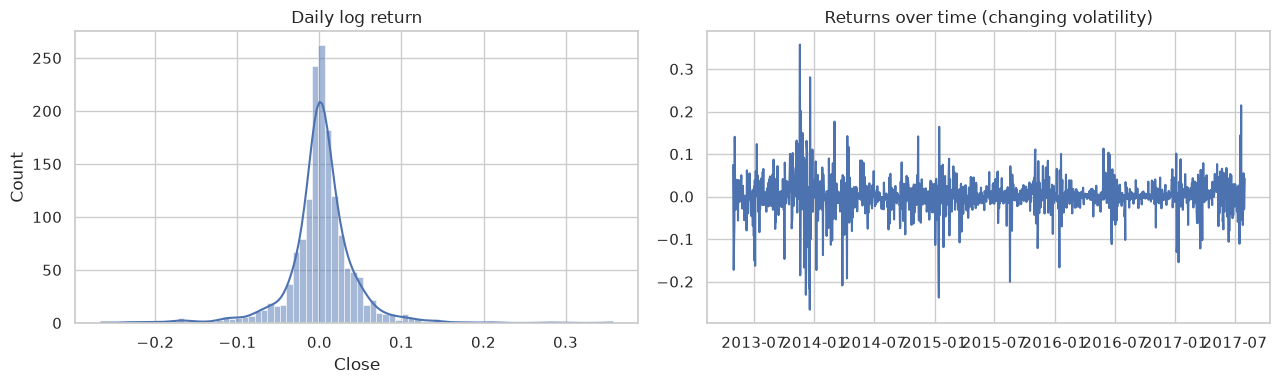

Mean 0.0020 | std 0.0426 | kurtosis 10.3 (heavy tails)

Five most extreme daily moves:
           Date  Return
204  2013-11-18   0.357
235  2013-12-19   0.281
234  2013-12-18  -0.266
626  2015-01-14  -0.238
222  2013-12-06  -0.231


In [5]:
ret = np.log(train['Close']).diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(ret, bins=80, kde=True, ax=ax[0]); ax[0].set_title('Daily log return')
ax[1].plot(train['Date'].iloc[1:], ret); ax[1].set_title('Returns over time (changing volatility)')
plt.tight_layout(); plt.show()
print(f'Mean {ret.mean():.4f} | std {ret.std():.4f} | kurtosis {ret.kurt():.1f} (heavy tails)')
print('\nFive most extreme daily moves:')
extreme = ret.abs().sort_values(ascending=False).head(5).index
print(pd.DataFrame({'Date': train.loc[extreme, 'Date'].dt.date, 'Return': ret[extreme].round(3)}))

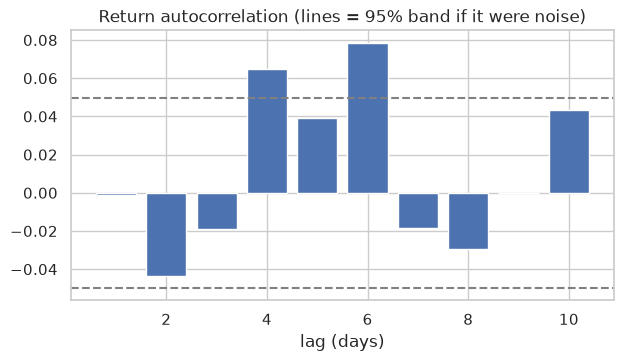

In [6]:
acf = [ret.autocorr(l) for l in range(1, 11)]
plt.figure(figsize=(7, 3.5)); plt.bar(range(1, 11), acf)
lim = 1.96 / np.sqrt(len(ret)); plt.axhline(lim, ls='--', c='gray'); plt.axhline(-lim, ls='--', c='gray')
plt.title('Return autocorrelation (lines = 95% band if it were noise)'); plt.xlabel('lag (days)')
plt.show()

**Findings**
- There are no missing or duplicated dates. Only `Volume` has nulls (the data does not exist before 2014) and it is not used as an input.
- The price grows exponentially: it is better to work with log returns.
- Returns have heavy tails (real extreme days, not data errors), so outliers are not removed.
- The autocorrelation of returns is weak, which anticipates that the history carries little signal.

## 4. Model (2 pts)

**Preprocessing:** features derived from the closing prices (`build_features`) and standardization inside a `Pipeline`.

**Temporal split (no shuffling):**
- *Training:* up to 180 days before the end of the training file.
- *Validation:* the last 180 days of the training file (model selection).
- *Test:* the August 2017 week, used once at the end. The features of each day only use data from previous days.

**Algorithms compared:** two baselines (*naive* = return 0, and *drift* = historical mean return) and three ML models: Ridge, Random Forest and Gradient Boosting, tuned with `GridSearchCV` and temporal cross-validation (`TimeSeriesSplit`).

In [7]:
full = pd.concat([train, test]).reset_index(drop=True)
close = full.set_index('Date')['Close']
X = build_features(close)
y = np.log(close.shift(-1) / close)                 # tomorrow's return (target)
next_price = close.shift(-1)

train_end = train['Date'].max(); val_start = train_end - pd.Timedelta(days=180)
valid = X.notna().all(axis=1) & y.notna()
m_trn = valid & (X.index < val_start)
m_val = valid & (X.index >= val_start) & (X.index < train_end)
m_tst = valid & (X.index >= train_end)
print(f'training {m_trn.sum()} | validation {m_val.sum()} | test {m_tst.sum()} rows')
print('First test target:', (next_price[m_tst].index + pd.Timedelta(days=1))[0].date(), '→ ...')

training 1346 | validation 180 | test 7 rows
First test target: 2017-08-01 → ...


In [8]:
tscv = TimeSeriesSplit(n_splits=5)
def pipe(est): return Pipeline([('scaler', StandardScaler()), ('model', est)])

grids = {
    'Ridge': (pipe(Ridge()), {'model__alpha': [1, 10, 100, 1000]}),
    'Random Forest': (pipe(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
                      {'model__min_samples_leaf': [5, 20, 50], 'model__max_depth': [3, 6]}),
    'Gradient Boosting': (pipe(GradientBoostingRegressor(subsample=0.8, random_state=RANDOM_STATE)),
                          {'model__n_estimators': [100, 200], 'model__max_depth': [2, 3],
                           'model__learning_rate': [0.01, 0.03]}),
}
best = {}
for name, (p, grid) in grids.items():
    gs = GridSearchCV(p, grid, cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X[m_trn], y[m_trn])
    best[name] = gs
    print(f'{name:18s} best parameters: {gs.best_params_}  | CV RMSE (return): {-gs.best_score_:.4f}')

Ridge              best parameters: {'model__alpha': 1000}  | CV RMSE (return): 0.0342


Random Forest      best parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 50}  | CV RMSE (return): 0.0342


Gradient Boosting  best parameters: {'model__learning_rate': 0.01, 'model__max_depth': 2, 'model__n_estimators': 100}  | CV RMSE (return): 0.0340


In [9]:
baselines = {
    'Naive baseline (tomorrow = today)': DummyRegressor(strategy='constant', constant=0.0).fit(X[m_trn], y[m_trn]),
    'Drift baseline (mean return)': DummyRegressor(strategy='mean').fit(X[m_trn], y[m_trn]),
}
models = {**baselines, **{n: gs.best_estimator_ for n, gs in best.items()}}

## 5. Evaluation (1 pt)
The predicted price is rebuilt (`close_today · exp(return)`) and the error is measured in dollars. An *R² of the return* close to 0 or negative means the model does not explain the daily variation. Directional accuracy is not defined for the naive baseline (it always predicts "no change").

In [10]:
def evaluate(model, mask):
    pred_ret = model.predict(X[mask])
    actual = next_price[mask].values; pred = close[mask].values * np.exp(pred_ret)
    direction = np.mean(np.sign(pred_ret) == np.sign(y[mask].values)) if np.any(pred_ret != 0) else np.nan
    return {'RMSE (USD)': np.sqrt(mean_squared_error(actual, pred)), 'MAE (USD)': mean_absolute_error(actual, pred),
            'MAPE (%)': np.mean(np.abs(actual - pred) / actual) * 100,
            'Return R²': r2_score(y[mask], pred_ret), 'Directional accuracy': direction}

val_table  = pd.DataFrame({n: evaluate(m, m_val) for n, m in models.items()}).T.round(3)
test_table = pd.DataFrame({n: evaluate(m, m_tst) for n, m in models.items()}).T.round(3)
print('VALIDATION (last 180 days of training; models trained on earlier data)'); display(val_table)
print('TEST (1 to 7 August 2017; 7 predictions)'); display(test_table)

VALIDATION (last 180 days of training; models trained on earlier data)


,RMSE (USD),MAE (USD),MAPE (%),Return R²,Directional accuracy
Naive baseline (tomorrow = today),87.805,57.963,3.058,-0.020,NaN
Drift baseline (mean return),87.568,57.450,3.028,-0.011,0.622
Ridge,87.961,57.157,3.018,-0.019,0.567
Random Forest,87.939,56.917,2.976,0.003,0.617
Gradient Boosting,87.720,57.701,3.041,-0.015,0.617


TEST (1 to 7 August 2017; 7 predictions)


,RMSE (USD),MAE (USD),MAPE (%),Return R²,Directional accuracy
Naive baseline (tomorrow = today),168.224,130.126,4.233,-0.209,NaN
Drift baseline (mean return),166.380,129.526,4.218,-0.183,0.571
Ridge,168.598,129.594,4.225,-0.216,0.429
Random Forest,174.604,138.373,4.504,-0.307,0.571
Gradient Boosting,168.340,132.481,4.307,-0.208,0.429


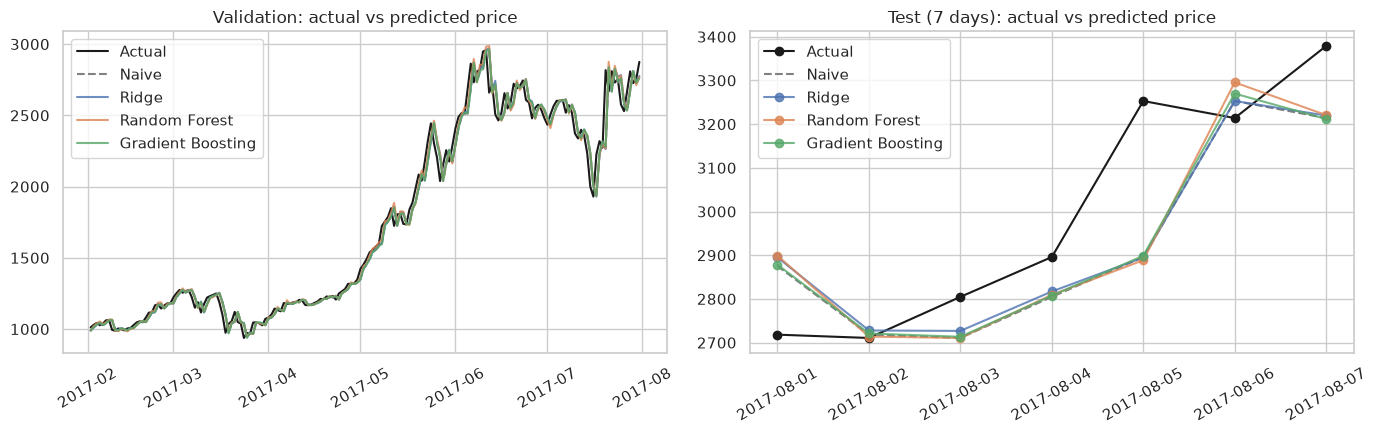

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ml = list(best)
idx_v = close[m_val].index + pd.Timedelta(days=1)
ax[0].plot(idx_v, next_price[m_val], 'k', label='Actual')
ax[0].plot(idx_v, close[m_val].values, '--', color='gray', label='Naive')
for n in ml: ax[0].plot(idx_v, close[m_val].values * np.exp(models[n].predict(X[m_val])), alpha=.8, label=n)
ax[0].set_title('Validation: actual vs predicted price'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=30)
idx_t = close[m_tst].index + pd.Timedelta(days=1)
ax[1].plot(idx_t, next_price[m_tst], 'ko-', label='Actual')
ax[1].plot(idx_t, close[m_tst].values, '--', color='gray', label='Naive')
for n in ml: ax[1].plot(idx_t, close[m_tst].values * np.exp(models[n].predict(X[m_tst])), 'o-', alpha=.8, label=n)
ax[1].set_title('Test (7 days): actual vs predicted price'); ax[1].legend(); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

Selected model (lowest validation RMSE among the ML models): Gradient Boosting


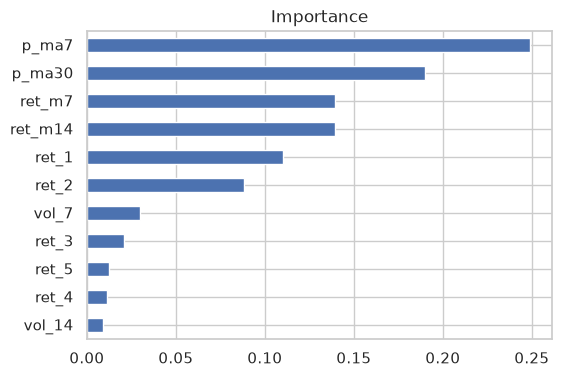

In [12]:
chosen = min(ml, key=lambda n: val_table.loc[n, 'RMSE (USD)'])
print('Selected model (lowest validation RMSE among the ML models):', chosen)
final = models[chosen][-1]
coefs = getattr(final, 'coef_', None)
label = 'Coefficient (standardized variables)' if coefs is not None else 'Importance'
coefs = coefs if coefs is not None else final.feature_importances_
pd.Series(coefs, index=FEATURES).sort_values().plot.barh(figsize=(6, 4), title=label); plt.show()

## 6. Conclusion (0.5 pt)

**How well does it work?** The three ML models end up **practically tied with the naive baseline**. On validation the RMSE is ~\$87.7–88.0 for all of them (naive: \$87.81; Gradient Boosting: \$87.72; Ridge: \$87.96; Random Forest: \$87.94), and in the test week the naive baseline (\$168.22) and Gradient Boosting (\$168.34) are almost identical, while Random Forest is worse (\$174.60). The *return R²* is close to 0 or negative in all cases: past returns and volatility do not explain the next day's variation.

**What was learned**
- The result is consistent with the efficient market hypothesis and with the almost null autocorrelation seen in the exploration: the price history alone carries very little information about tomorrow's price.
- The directional accuracy (~57–62% on validation) should not be read as skill: the *drift* baseline, which always predicts the average rise, gets the same, because bitcoin went up in that period.
- Predicting the return and rebuilding the price avoided the extrapolation problem of the trees (the test price, ~\$3,000, is above almost all the training range).
- The test week has only 7 points, so those differences are not statistically significant; the 180-day validation is the most reliable comparison.

**Chosen model:** Gradient Boosting (lowest validation RMSE among the ML models), retrained with all the data for the API.

**Limitations and possible improvements:** include external variables (volume, social-media sentiment, other markets), try sequence models (LSTM/GRU, as in McNally et al., 2018), predict several days or an uncertainty interval instead of a single value. Also, the dataset ends in August 2017: "tomorrow" in the API is 2017-08-08, unless recent closing prices are sent with `recent_closes`.

## Export the model
The chosen model is **retrained with all the available data** (training + validation + test week) and saved together with the last 60 closing prices, so the API can predict "tomorrow" without receiving data.

In [13]:
from sklearn.base import clone
final_model = clone(models[chosen]).fit(X[valid], y[valid])

bundle = {
    'pipeline': final_model, 'model': chosen, 'features': FEATURES, 'sklearn': sklearn.__version__,
    'history': {'dates': [d.date().isoformat() for d in close.index[-60:]], 'closes': close.iloc[-60:].round(2).tolist()},
    'validation_metrics': val_table.loc[chosen].to_dict(), 'test_metrics': test_table.loc[chosen].to_dict(),
}
joblib.dump(bundle, '../models/bitcoin.joblib', compress=3)
print('Saved ../models/bitcoin.joblib | last data point:', bundle['history']['dates'][-1])

# API contract check
from predictors.bitcoin import predict
predict({})

Saved ../models/bitcoin.joblib | last data point: 2017-08-07


{'prediction': 3385.49,
 'unit': 'USD',
 'current_price': 3378.94,
 'change_pct': 0.19,
 'model': 'Gradient Boosting',
 'note': 'Academic reference; not financial advice.',
 'base_date': '2017-08-07',
 'prediction_date': '2017-08-08'}